# 08 — Binary Whale Optimization Algorithm (BWOA) for feature selection

Continuous algorithm: *Mirjalili S., Lewis A. (2016). The whale optimization algorithm. Adv. Eng. Softw.*  
Binarised with the **Unified Binarization Framework (UBF)**: deterministic sign mapping, density-diverse initial population, fitness memoisation and elite bit-flip local search. RS = random-search control under the same framework. Protocol: see `00_data_and_protocol`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from fsbench import experiment as ex, plots
pd.set_option("display.width", 200, "display.max_columns", 40)

In [2]:
METHOD = "WOA"
recs = ex.run_method(METHOD)
base = {m: ex.run_method(m) for m in ("ANOVA", "Chi2", "AllFeatures", "RS")}
df = ex.flatten(recs)
print(len(recs), "runs")

80 runs


## Performance on the test split (mean ± std over 10 runs)

In [3]:
plots.summary_table(df, by=("dataset", "classifier"))

,dataset,classifier,accuracy,precision_macro,recall_macro,f1_macro,auc_macro,n_selected,search_time_s
0,dermatology,ANN,0.9691 ± 0.0098,0.969 ± 0.0097,0.9643 ± 0.0114,0.9656 ± 0.0107,0.9973 ± 0.0015,17.5 ± 2.6352,4.038 ± 0.5521
1,dermatology,DT,0.9473 ± 0.0165,0.9446 ± 0.0185,0.9348 ± 0.0228,0.9382 ± 0.0208,0.9621 ± 0.0129,17.5 ± 2.6352,4.038 ± 0.5521
2,dermatology,KNN,0.9464 ± 0.0174,0.9421 ± 0.0171,0.9389 ± 0.0241,0.9384 ± 0.0206,0.9947 ± 0.0049,17.5 ± 2.6352,4.038 ± 0.5521
3,dermatology,RF,0.9682 ± 0.015,0.9679 ± 0.0171,0.9628 ± 0.0164,0.9642 ± 0.0165,0.9975 ± 0.0016,17.5 ± 2.6352,4.038 ± 0.5521
4,dermatology,SVM,0.9627 ± 0.0125,0.9639 ± 0.0145,0.9563 ± 0.0133,0.9578 ± 0.0135,0.9971 ± 0.0016,17.5 ± 2.6352,4.038 ± 0.5521
5,dermatology,XGB,0.9536 ± 0.0179,0.9509 ± 0.0204,0.9448 ± 0.0219,0.9467 ± 0.0214,0.9944 ± 0.0025,17.5 ± 2.6352,4.038 ± 0.5521
6,ionosphere,ANN,0.8858 ± 0.0144,0.8863 ± 0.014,0.8628 ± 0.019,0.8722 ± 0.0168,0.9283 ± 0.03,7.4 ± 2.4129,4.0365 ± 0.7837
7,ionosphere,DT,0.9009 ± 0.0135,0.8938 ± 0.0158,0.8909 ± 0.0154,0.892 ± 0.0149,0.8904 ± 0.0155,7.4 ± 2.4129,4.0365 ± 0.7837
8,ionosphere,KNN,0.8811 ± 0.0214,0.895 ± 0.0175,0.847 ± 0.0292,0.863 ± 0.0265,0.9254 ± 0.0191,7.4 ± 2.4129,4.0365 ± 0.7837
9,ionosphere,RF,0.9151 ± 0.0183,0.9121 ± 0.0197,0.9019 ± 0.021,0.9065 ± 0.0204,0.9667 ± 0.0142,7.4 ± 2.4129,4.0365 ± 0.7837


## Comparison with the classical filters (F1-macro, averaged over the six classifiers)

In [4]:
allb = pd.concat([df] + [ex.flatten(r) for r in base.values()])
pivot = allb.groupby(["dataset", "method"]).f1_macro.mean().unstack().round(4)
pivot

method,ANOVA,AllFeatures,Chi2,RS,WOA
dataset,,,,,
dermatology,0.9676,0.9568,0.9568,0.9552,0.9518
ionosphere,0.8734,0.8907,0.8734,0.8765,0.8862
musk1,0.8449,0.8634,0.8603,0.8553,0.8558
sonar,0.8293,0.8317,0.8188,0.7940,0.7770
spectf,0.5448,0.5448,0.5448,0.5471,0.5465
vehicle,0.6656,0.7311,0.6558,0.7273,0.7205
wdbc,0.9294,0.9442,0.9462,0.9291,0.9397
wine,0.9628,0.9524,0.9542,0.9530,0.9523


In [5]:
allb.groupby(["dataset", "method"])[["n_selected", "search_time_s"]].mean().unstack().round(2)

n_selected                                search_time_s                               
method           ANOVA AllFeatures   Chi2    RS   WOA         ANOVA AllFeatures  Chi2     RS   WOA
dataset                                                                                           
dermatology       24.0        34.0   34.0  18.1  17.5          0.36         0.0  0.23  13.37  4.04
ionosphere         3.0        33.0    3.0   6.4   7.4          0.33         0.0  0.32  15.02  4.04
musk1             66.0       166.0  133.0  55.9  79.6          0.38         0.0  0.28  21.06  7.17
sonar             24.0        60.0   30.0  21.5  20.9          0.30         0.0  0.28  11.13  4.23
spectf            44.0        44.0   44.0  16.9  25.8          0.31         0.0  0.20  12.17  2.99
vehicle            9.0        18.0    7.0  10.1  10.6          0.46         0.0  0.49  28.40  5.22
wdbc              18.0        30.0   21.0   9.9  10.9          0.37         0.0  0.35  20.84  5.47
wine               9.0        13.0    8.0   5.8   5.9          0.18         0.0  0.19   7.11  1.44

## Convergence: best-so-far fitness per iteration
A flat tail means the search converged within the budget; a still-decreasing tail means more iterations could help.

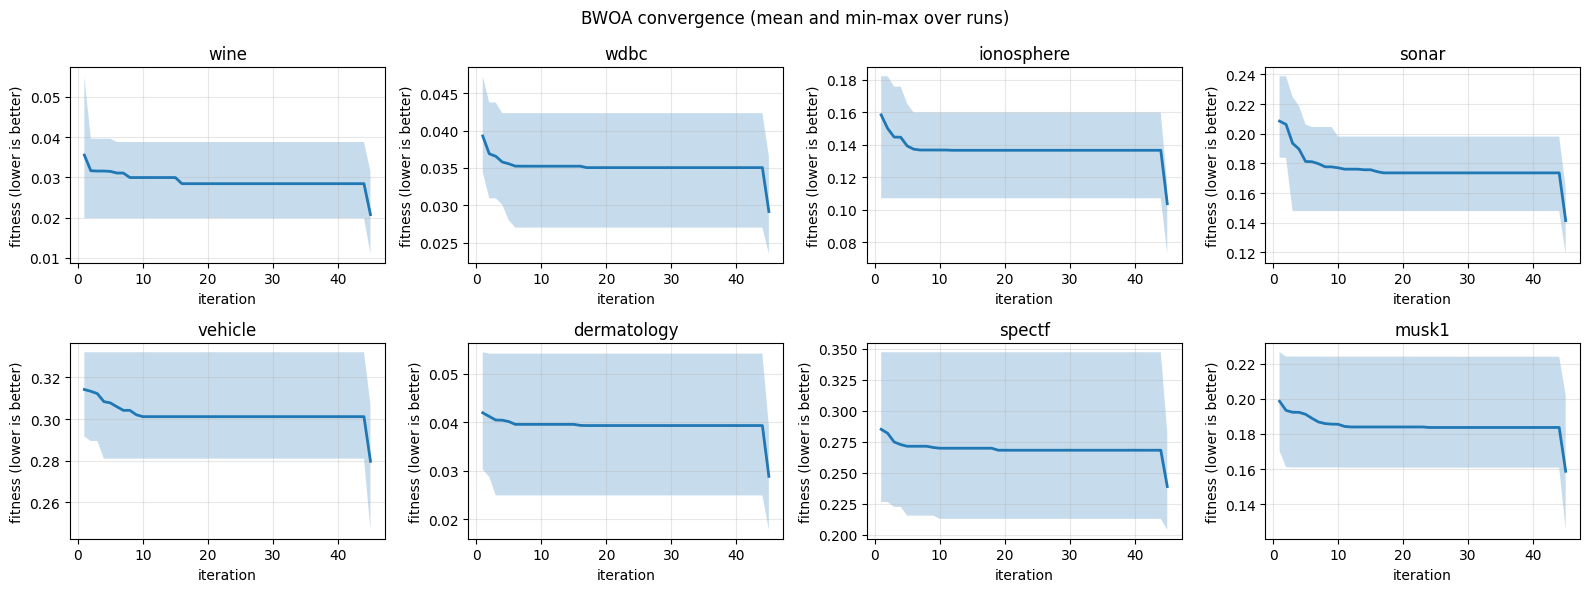

In [6]:
plots.convergence(recs, title="BWOA convergence (mean and min-max over runs)", name="convergence_WOA");

## Confusion matrices and ROC curves (run 0, KNN)

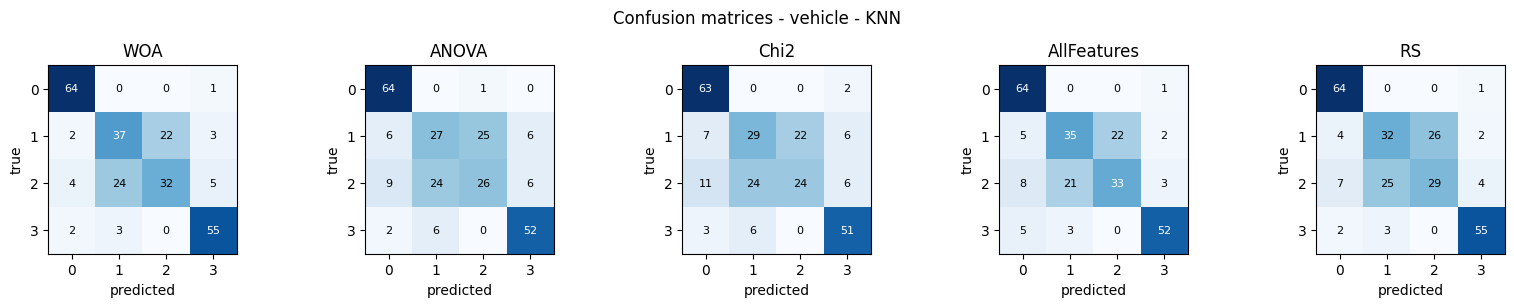

In [7]:
ds = "vehicle"
plots.confusion_matrices({METHOD: recs, **base}, ds, name=f"cm_{METHOD}_{ds}");

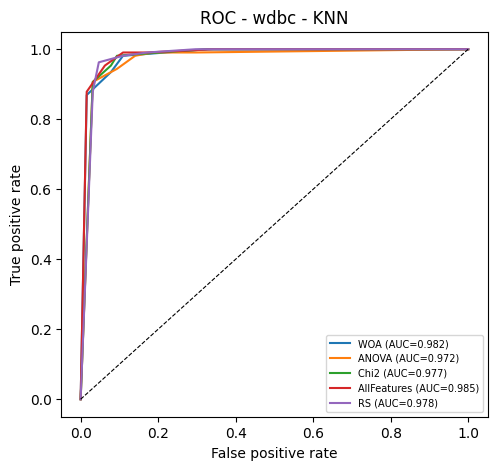

In [8]:
plots.roc_curves({METHOD: recs, **base}, "wdbc", name=f"roc_{METHOD}_wdbc");

## Computation
`n_classifier_fits` counts real classifier trainings; `cache_hits` are FEs served by the memo.

In [9]:
pd.DataFrame([{k: r[k] for k in ("dataset", "run", "n_selected", "time_s", "n_classifier_fits", "cache_hits")} for r in recs]).groupby("dataset").mean().round(2)

,run,n_selected,time_s,n_classifier_fits,cache_hits
dataset,,,,,
dermatology,4.5,17.5,4.04,161.7,838.3
ionosphere,4.5,7.4,4.04,153.3,846.7
musk1,4.5,79.6,7.17,273.0,727.0
sonar,4.5,20.9,4.23,228.6,771.4
spectf,4.5,25.8,2.99,166.4,833.6
vehicle,4.5,10.6,5.22,110.6,889.4
wdbc,4.5,10.9,5.47,153.6,846.4
wine,4.5,5.9,1.44,74.9,925.1
